# 금융 콜센터 고객 문의 유형 분류
### 고객의 첫 질문만 보고 문의 유형을 자동으로 나누기 — TF-IDF + 분류 모델

**환경:** Google Colab (인터넷 연결 필요)
**준비물 (파일 2개)**
| 파일 | 내용 |
|---|---|
| 상담 대화 `.txt` 파일 | 은행·카드·보험 콜센터 상담 대화 4,205건 (`[A4075]` 같은 번호 아래 `고객:`/`상담사:` 발화) |
| `inquiry_labels.csv` | 대화 번호별 **정답 문의 유형** (원래 파일에는 정답이 없어서 따로 만든 파일) |

**소요 시간:** 약 40분

## 오늘의 상황
> 금융회사 콜센터에 하루에도 수천 건의 문의가 들어옵니다.
> 고객이 **첫마디를 말하는 순간** 문의 유형을 자동으로 알아내면, 알맞은 담당 부서로 바로 연결할 수 있습니다.

## 분류할 문의 유형 (5개)
| 유형 | 예 |
|---|---|
| 은행·카드 | 인터넷뱅킹 로그인, 통장·카드 분실, 잘못 보낸 이체, 보이스피싱 |
| 자동차보험 | 교통사고 처리, 과실 비율, 긴급출동, 자동차보험 할증 |
| 질병·상해 보험금 | 실손(실비) 청구, 암·수술 보장, 골절 진단금, 치아보험 |
| 재물·배상 보험 | 화재·누수, 여행 중 휴대품 파손·도난, 남에게 끼친 손해(일상배상) |
| 보험 계약·보험료 | 가입·해지, 보험료 연체, 만기·휴면보험금, 청구 절차 일반 |

## 실습 진행 과정
| 단계 | 할 일 | 산출물 |
|---|---|---|
| 0. 준비 | 설치, 파일 2개 읽기 | 대화 수 |
| 1. 텍스트 전처리 | 대화 나누기 → 중복 제거 → **고객 첫 질문** 뽑기 → 단어 나누기 | 대화 표 |
| 2. 정제 데이터셋 | 정답 붙이기, 유형 분포 확인, CSV 저장 | `inquiry_dataset.csv` |
| 3. 텍스트 분석 | 학습/평가 나누기 → TF-IDF → 분류 모델 3개 비교 | 학습된 모델 |
| 4. 분석 결과 | 성적표, 혼동 행렬, 유형별 핵심 단어, 틀린 사례, **새 문의 넣어 보기** | 그래프, `predictions.csv` |
| 정리 | 한계 | — |

> **실행 방법:** 셀을 클릭하고 `Shift + Enter`. 반드시 **위에서부터 순서대로** 실행하세요.
> ✏️ 표시가 있는 곳은 **직접 바꿔 볼 수 있는 부분**입니다.

---
## 0. 준비
| 도구 | 하는 일 |
|---|---|
| `kiwipiepy` | 한국어 형태소 분석기 Kiwi (단어 나누기) |
| `koreanize-matplotlib` | 그래프에 한글 글꼴(나눔고딕) 설정 |
| `scikit-learn` | TF-IDF, 분류 모델, 평가 (Colab에 기본 설치) |

In [1]:
# 도구 설치 (처음 한 번만)
# !           : 이 줄을 파이썬이 아닌 터미널 명령으로 실행
# pip install : 파이썬 도구(패키지)를 내려받아 설치하는 명령
# -q          : 설치 과정 메시지를 줄여서 출력
# kiwipiepy            : 한국어 형태소 분석기 Kiwi
# koreanize-matplotlib : 그래프에 한글 글꼴(나눔고딕)을 설정해 주는 도구
!pip install -q kiwipiepy koreanize-matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 MB 11.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 84.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 126.1 MB/s eta 0:00:00


> 🔧 다음 셀에서 `PIL` 관련 `ImportError`가 나면: 메뉴 **런타임 → 세션 다시 시작** 후 설치 셀은 건너뛰고 다음 셀부터 실행하세요.

Colab 왼쪽 **📁 파일 창**에 **상담 대화 `.txt` 파일**과 **`inquiry_labels.csv`** 를 끌어다 놓으세요.

In [2]:
# glob   : 파일 이름을 패턴으로 찾는 파이썬 기본 도구
# pandas : 표(DataFrame)를 다루는 도구, pd라는 짧은 이름으로 불러옴
import glob
import pandas as pd

# 파일 창에서 .txt 파일 찾기 (상담 대화 파일 하나만 올려 두세요)
# glob.glob("*.txt"): 현재 폴더에서 이름이 .txt로 끝나는 파일 경로들을 리스트로 돌려줌
# [0]: 그 리스트의 첫 번째 파일 (txt 파일이 없으면 IndexError 발생)
txt_path = glob.glob("*.txt")[0]

# 대화 파일 전체를 글자 하나로 읽기
# open(경로, encoding="utf-8"): 파일을 UTF-8(한글을 저장하는 방식)로 열기
# .read(): 파일 내용 전체를 문자열 하나로 읽어 옴
text = open(txt_path, encoding="utf-8").read()

# 정답 파일 읽기 (열: ID, 유형)
# pd.read_csv(파일 이름): CSV 파일을 읽어 표로 만듦
labels = pd.read_csv("inquiry_labels.csv")

# 찾은 대화 파일 이름과 정답 파일의 행 수 출력
print("대화 파일:", txt_path)
print("정답 파일 행 수:", len(labels))

# 파일 앞부분 400글자 보기
# text[:400]: 문자열의 처음부터 400번째 글자 앞까지
print(text[:400])

대화 파일: 금융보험_사고_및_보상_문의_대화내용.txt
정답 파일 행 수: 3264
[A4075]
고객: 인터넷뱅킹 로그인이 안돼요?
상담사: 혹시 비밀번호를 잊어버리셨나요?
고객: 알고 있는 번호를 했는데 다 안된다고 나와요
상담사: 비밀번호 5회이상 잘못 입력하셨나요?
고객: 어제 2번해서 안되서 오늘 다시 들어갔는데 안되요
상담사: 인터넷뱅킹 로그인시 비밀번호 5회이상 틀리시면 로그인이 불가능합니다
고객: 오늘은 3번밖에 안 했는데요?
상담사: 비밀번호 오류횟수가 누적 5회상이면 이용하실 수 없습니다.
고객: 다시 인터넷뱅킹에 로그인 하려면 어떻게 하면 되나요?
상담사: 은행을 방문하셔서 비밀번호 오류를 해제하고 새 비밀번호를 등록하면 다시 이용하실 수 있습니다.
고객: 그것만 하면 되나요?
상담사: 은행 출금계좌번호와 비밀번호, 보안매체. 본인인증이 필요합니다.
고객: 본인인증하기가


---
## 1. 텍스트 데이터 전처리

### 💡 이 데이터의 특징
| 특징 | 예 | 처리 방법 |
|---|---|---|
| 대화마다 `[번호]` 줄로 시작 | `[A4075]` | 이 줄을 기준으로 대화 나누기 |
| 줄마다 말한 사람 표시 | `고객: …`, `상담사: …` | 고객 발화만 따로 모으기 |
| **완전히 같은 대화가 반복** | 같은 내용이 여러 번 들어 있음 | 중복 제거 |
| 첫 발화가 **인사뿐** | `안녕하세요? OO보험이지요?` | 인사뿐인 발화는 건너뛰고 첫 **질문** 찾기 |
| 개인정보 가림 표시 | `OOO`, `000000-0000000` | 지우기 |

### 1-1. 대화 나누기

In [3]:
# re: 정규표현식(글자 패턴) 도구
import re

# '[A숫자]' 줄을 기준으로 자르기 → ['', 'A4075', '대화 내용', 'A4076', '대화 내용', ...]
# 패턴 설명
#   ^ ... $   : 한 줄 전체 (flags=re.M 덕분에 ^와 $가 줄마다의 처음·끝을 뜻함)
#   \[ \]     : 대괄호 글자 자체 ([ ]는 정규표현식에서 특수 기호라서 \ 를 붙임)
#   (A\d+)    : A 다음에 숫자 1개 이상 → 괄호로 묶어서 잘린 결과에 번호도 함께 남김
#   \s*       : 줄 끝의 공백이 있어도 됨
# re.split(패턴, 글자): 패턴이 나오는 곳마다 글자를 잘라 리스트로 돌려줌
parts = re.split(r"^\[(A\d+)\]\s*$", text, flags=re.M)

# 번호와 대화 내용을 짝지어 표로 만들기 (parts[1::2] = 번호들, parts[2::2] = 대화 내용들)
#   [1::2] : 1번 칸부터 2칸씩 건너뛰며 꺼냄 → 번호들
#   [2::2] : 2번 칸부터 2칸씩 건너뛰며 꺼냄 → 대화 내용들
#   p.strip() : 대화 내용 앞뒤의 빈 줄과 공백 제거
df = pd.DataFrame({"ID": parts[1::2], "원문": [p.strip() for p in parts[2::2]]})

# 대화 수(표의 행 수) 출력
print("대화 수:", len(df))

# 완전히 같은 대화 지우기
# drop_duplicates("원문"): '원문'이 똑같은 행은 처음 것만 남기고 지움
# reset_index(drop=True): 행 번호를 0부터 다시 매김
df = df.drop_duplicates("원문").reset_index(drop=True)

# 중복을 지운 뒤의 대화 수 출력
print("중복 제거 후:", len(df))

대화 수: 4205
중복 제거 후: 3781


### 1-2. 고객 첫 질문 뽑기
1. 대화에서 `고객:`으로 시작하는 줄만 모읍니다.
2. 가림 표시(`OO`, `000`)를 지우고 띄어쓰기를 정리합니다.
3. **인사뿐인 사용자 메시지**(인사말·회사 이름만 있는 사용자 메시지)는 건너뛰고, 처음으로 나오는 **질문**을 고릅니다.

In [6]:
# ✏️ 인사 사용자 사용자 메시지메시지에서 지울 표현 (지우고 나서 남는 글자가 없으면 '인사뿐인 ')
# |는 '또는', [\s.?!,~]는 공백 문자나 . ? ! , ~ 중 하나
GREETING = r"안녕하세요|안녕하십니까|수고하십니다|수고많으십니다|여보세요|반갑습니다|보험|은행|카드|콜센터|고객센터|이지요|이죠|인가요|맞나요|네|[\s.?!,~]"

# 대화 하나에서 고객 첫 질문을 찾는 함수
# dialog: 대화 하나의 원문 (여러 줄로 된 문자열)
def first_question(dialog):
    # splitlines(): 대화를 줄 단위 리스트로 나눠 한 줄씩 꺼냄
    for line in dialog.splitlines():
        # startswith("고객:"): 줄이 '고객:'으로 시작하는지 확인
        if not line.startswith("고객:"):
            continue                                              # 상담사 사용자 메시지는 건너뛰기
        q = line[3:]                                              # '고객:' 세 글자 떼기
        # O{2,}: O가 2개 이상 이어진 부분, 0{3,}: 0이 3개 이상 이어진 부분 → 빈 글자로 바꿈
        q = re.sub(r"O{2,}|0{3,}", "", q)                         # 가림 표시 지우기
        # \s+: 공백이 1개 이상 이어진 부분 → 한 칸으로, strip(): 앞뒤 공백 제거
        q = re.sub(r"\s+", " ", q).strip()                        # 띄어쓰기 정리
        # 조건 1: 글자 수가 5 이상
        # 조건 2: 인사 표현을 모두 지워도 남는 글자가 있음 (인사뿐인 사용자 메시지가 아님)
        if len(q) >= 5 and re.sub(GREETING, "", q) != "":
            return q                                              # 인사가 아닌 첫 사용자 메시지를 돌려줌
    return ""                                                     # 질문이 없으면 빈 글자

# 모든 대화에 first_question 함수를 적용해 '첫질문' 열을 만듦
# .apply(함수): 열의 값마다 함수를 실행해 결과를 모음
df["첫질문"] = df["원문"].apply(first_question)

# 결과 예시 5개
# head(): 표의 앞 5행 보기
df[["ID", "첫질문"]].head()

,ID,첫질문
0,A4075,인터넷뱅킹 로그인이 안돼요?
1,A4076,미성년 자녀도 인터넷뱅킹 가능한가요?
2,A4079,공인인증서를 온라인에서 발급 가능한가요?
3,A4080,문의 좀 드리려구요 BC카드를 처음 발급 받았는데요.
4,A4081,안녕하세요. 공인인증서 관련해서 문의좀 드리려구요


### 1-3. 단어 나누기
TF-IDF에 넣을 **단어 목록**을 만듭니다. 문의 유형을 가르는 데 쓸모 있는 품사만 남깁니다.

| 남기는 품사 | 예 |
|---|---|
| 명사 (NNG, NNP) | `카드`, `분실`, `교통사고` |
| 동사·형용사 (VV, VA) | `잃어버리`, `다치` |
| 어근 (XR), 부사 (MAG) | `깨끗`, `안` |
| 외국어 (SL) | `OTP`, `MRI` |

In [7]:
# Kiwi: 한국어 형태소 분석기 클래스
from kiwipiepy import Kiwi

# Kiwi 분석기 만들기 (처음 만들 때 사전을 불러오느라 몇 초 걸림)
kiwi = Kiwi()

# 남길 품사
# NNG 일반명사, NNP 고유명사, VV 동사, VA 형용사, XR 어근, MAG 부사, SL 외국어
KEEP = {"NNG", "NNP", "VV", "VA", "XR", "MAG", "SL"}

# 문장 하나 → 띄어쓰기로 이은 단어 목록
# kiwi.tokenize(문장): 형태소(토큰) 목록, 각 토큰 t는 t.form(글자)과 t.tag(품사 태그)를 가짐
# t.tag.split("-")[0]: 'VA-I'처럼 뒤에 붙은 표시를 떼고 'VA'만 남김
# " ".join(...): 남긴 글자들을 띄어쓰기로 이어 문자열 하나로 만듦
def to_words(sentence):
    return " ".join(t.form for t in kiwi.tokenize(sentence) if t.tag.split("-")[0] in KEEP)

# 모든 첫 질문을 단어 목록으로 바꾸기 (20초 정도 걸림)
# '첫질문' 열의 문장마다 to_words를 실행해 '단어' 열을 만듦
df["단어"] = df["첫질문"].apply(to_words)

# 0번 문의의 원래 문장과 단어 목록 비교
print(df["첫질문"][0])
print(df["단어"][0])

인터넷뱅킹 로그인이 안돼요?
인터넷 뱅킹 로그인 안 되


---
## 2. 정제 데이터셋

### 💡 정답(문의 유형)은 어떻게 만들었나요?
원래 대화 파일에는 정답이 없습니다. 그래서 다음 순서로 `inquiry_labels.csv`를 미리 만들었습니다.
1. 대화 전체(고객 + 상담사)에서 유형별 키워드 수를 세어 가장 많은 유형을 임시 정답으로 정함
2. **사람이 모든 대화의 앞부분을 읽고** 틀린 정답을 고침 (임시 정답의 약 15%가 바뀜)
3. 다섯 유형 어디에도 맞지 않는 대화(인사만 있는 대화, 컴퓨터 고장 문의 등)와 첫 질문이 똑같은 대화는 정답 파일에서 뺌

> ⚠️ 한 사람이 정한 정답이라 **틀린 정답이 섞여 있을 수 있습니다.** 이 점은 정리에서 다시 다룹니다.

In [8]:
# 정답 파일과 합치기: 두 표에 모두 있는 ID만 남김 (how="inner")
# df.merge(labels, on="ID"): 'ID' 열 값이 같은 행끼리 이어 붙여 '유형' 열을 추가
data = df.merge(labels, on="ID", how="inner")

# 첫 질문이 똑같은 대화가 남아 있으면 하나만 남기기
# drop_duplicates("첫질문"): '첫질문'이 같은 행은 처음 것만 남김
# reset_index(drop=True): 행 번호를 0부터 다시 매김
data = data.drop_duplicates("첫질문").reset_index(drop=True)

# 정제된 문의 수 출력
print("정제된 문의 수:", len(data))

# 저장 (utf-8-sig: 엑셀 한글 깨짐 방지)
# 네 개 열만 골라 CSV 파일로 저장, index=False는 행 번호를 저장하지 않음
data[["ID", "첫질문", "단어", "유형"]].to_csv("inquiry_dataset.csv", index=False, encoding="utf-8-sig")

# 무작위로 5행 보기 (random_state=1: 매번 같은 5행이 뽑히게 고정)
data[["ID", "첫질문", "유형"]].sample(5, random_state=1)

정제된 문의 수: 3238


,ID,첫질문,유형
2161,A19126,여행 중에 선글라스가 파손되어서요,재물·배상 보험
1603,A12381,"얼마전 통증치료 받았어요,보상되나요?",질병·상해 보험금
2248,A19279,핸드폰 어플로 보험금을 청구할 수 있다던데요?,보험 계약·보험료
2354,A19473,"요번에 아파트 주차장에 주차해뒀던 제차 범퍼를 긁어 수리를 맡겨야 되는데, 몇가지 ...",자동차보험
2430,A19675,요번에 새로 산 폰인데 아이가 가지고 있다 떨어트려 깨졌네요. 보상은 어떻게 받아야하죠?,재물·배상 보험


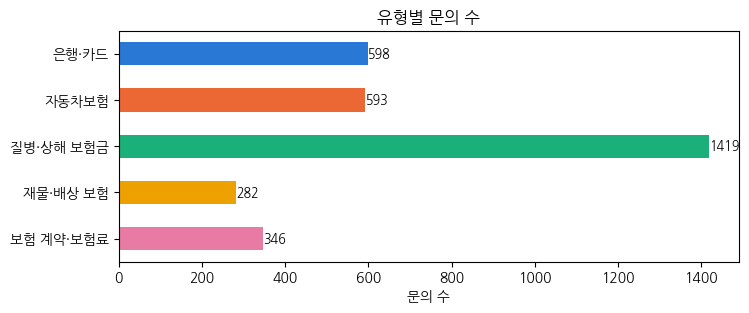

In [9]:
# matplotlib.pyplot: 그래프 그리기 도구, plt라는 짧은 이름으로 불러옴
import matplotlib.pyplot as plt
import koreanize_matplotlib                    # 불러오기만 하면 그래프 한글 글꼴(나눔고딕)이 설정됨

# 유형 순서와 유형별 색 (모든 그래프 공통)
# ORDER: 표와 그래프에서 유형을 늘어놓을 순서
ORDER = ["은행·카드", "자동차보험", "질병·상해 보험금", "재물·배상 보험", "보험 계약·보험료"]
# zip(A, B): 유형과 색 코드를 같은 위치끼리 짝지음 → dict(...)로 {유형: 색} 사전 만들기
COLORS = dict(zip(ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))

# 유형별 문의 수 가로 막대
# value_counts(): 유형마다 문의 수를 셈, reindex(ORDER): ORDER 순서로 다시 정렬
counts = data["유형"].value_counts().reindex(ORDER)

# plot.barh(): 가로 막대그래프, color: 유형 순서대로 색 지정, figsize: 그림 크기(가로, 세로)
ax = counts.plot.barh(color=[COLORS[k] for k in ORDER], figsize=(8, 3))

# 막대 끝에 문의 수 숫자 표시
ax.bar_label(ax.containers[0], fontsize=9)
ax.invert_yaxis()                                # 위에서부터 ORDER 순서대로

# x축 이름, y축 이름(비움), 그래프 제목
ax.set_xlabel("문의 수")
ax.set_ylabel("")
ax.set_title("유형별 문의 수")

# 그래프 화면에 표시
plt.show()

✅ **결과 확인:** 질병·상해 보험금이 가장 많고, 재물·배상 보험이 가장 적습니다. 이렇게 **유형별 개수 차이가 크면** 정확도만 보면 착각하기 쉬워서, 3단계에서 **macro-F1**도 함께 봅니다.

---
## 3. 텍스트 분석: 분류 모델 학습

### 3-1. 학습용 / 평가용 나누기
모델이 **처음 보는 문의**도 잘 맞히는지 확인하려고, 데이터의 20%는 학습에 쓰지 않고 평가용으로 남겨 둡니다.
- `stratify`: 학습용과 평가용의 유형 비율을 똑같이 맞춤
- `random_state`: 매번 같은 방식으로 나뉘게 고정

In [10]:
# train_test_split: 데이터를 학습용과 평가용으로 나누는 함수
from sklearn.model_selection import train_test_split

# 80%는 학습용, 20%는 평가용
#   data["단어"]          : 입력 (X) — 문의의 단어 목록
#   data["유형"]          : 정답 (y) — 문의 유형
#   test_size=0.2         : 20%를 평가용으로
#   random_state=42       : 매번 같은 방식으로 나뉘게 고정
#   stratify=data["유형"] : 학습용과 평가용의 유형 비율을 똑같이 맞춤
# 결과 4개: 학습용 입력, 평가용 입력, 학습용 정답, 평가용 정답
X_train, X_test, y_train, y_test = train_test_split(
    data["단어"], data["유형"], test_size=0.2, random_state=42, stratify=data["유형"])

# 학습용과 평가용 문의 수 출력
print("학습용:", len(X_train), " 평가용:", len(X_test))

학습용: 2590  평가용: 648


### 3-2. TF-IDF로 숫자 바꾸기
| 용어 | 뜻 |
|---|---|
| TF (단어 빈도) | 이 문의에 그 단어가 몇 번 나왔나 |
| IDF (역문서 빈도) | 그 단어가 **여러 문의에 흔하게** 나오면 점수를 낮춤 (`문의`, `하다` 같은 단어) |
| TF-IDF | 두 값을 곱한 점수 → **이 문의를 특징짓는 단어**일수록 높음 |

> ⚠️ `fit`(단어 사전 만들기)은 **학습용에만** 합니다. 평가용 단어까지 미리 보면 시험 문제를 미리 본 셈이 됩니다.

In [11]:
# TfidfVectorizer: 문장들을 TF-IDF 숫자 표(행렬)로 바꾸는 도구
from sklearn.feature_extraction.text import TfidfVectorizer

# analyzer=str.split: 이미 띄어쓰기로 나눠 둔 단어를 그대로 사용
tfidf = TfidfVectorizer(analyzer=str.split)

# 학습용으로 단어 사전을 만들고(fit) 숫자로 바꾸기(transform), 평가용은 바꾸기만
# A_train: (학습용 문의 수 × 단어 사전 크기) 행렬, 칸마다 그 문의에서 그 단어의 TF-IDF 점수
A_train = tfidf.fit_transform(X_train)
# A_test: 학습용으로 만든 단어 사전 그대로 평가용을 숫자로 바꿈 (사전에 없는 단어는 무시)
A_test = tfidf.transform(X_test)

# vocabulary_: {단어: 열 번호} 사전 → 길이가 곧 단어 사전 크기
print("단어 사전 크기:", len(tfidf.vocabulary_))
# shape: (행 수, 열 수)
print("학습용 행렬 크기:", A_train.shape)

단어 사전 크기: 1869
학습용 행렬 크기: (2590, 1869)


### 3-3. 분류 모델 3개 비교
| 모델 | 특징 |
|---|---|
| 나이브 베이즈 (`MultinomialNB`) | 단어 확률로 계산하는 빠르고 단순한 모델 (기준선) |
| 로지스틱 회귀 (`LogisticRegression`) | 단어마다 유형별 **가중치**를 배워서 점수를 매김 |
| 로지스틱 회귀 + 균형 (`class_weight="balanced"`) | 개수가 적은 유형을 틀리면 더 크게 벌점을 줌 |

| 평가 지표 | 뜻 |
|---|---|
| 정확도 (accuracy) | 전체 중 맞힌 비율 |
| macro-F1 | 유형마다 F1을 구해 **똑같은 비중으로 평균** → 개수가 적은 유형도 똑같이 중요하게 봄 |

In [12]:
# MultinomialNB       : 나이브 베이즈 분류 모델
# LogisticRegression  : 로지스틱 회귀 분류 모델
# accuracy_score, f1_score : 정확도와 F1 점수를 계산하는 함수
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# 비교할 모델 3개 (max_iter: 학습 반복 횟수 한도)
# {모델 이름: 모델} 사전, class_weight="balanced": 개수가 적은 유형에 가중치를 더 줌
models = {
    "나이브 베이즈": MultinomialNB(),
    "로지스틱 회귀": LogisticRegression(max_iter=1000),
    "로지스틱 회귀(균형)": LogisticRegression(max_iter=1000, class_weight="balanced"),
}

# 모델마다 학습(fit) → 평가용 예측(predict) → 점수 계산
# 모델별 점수를 모을 빈 리스트
rows = []
# models.items(): (모델 이름, 모델)을 하나씩 꺼냄
for name, model in models.items():
    # 학습용 행렬과 정답으로 모델 학습
    model.fit(A_train, y_train)
    # 평가용 행렬로 유형 예측
    pred = model.predict(A_test)
    # 정확도와 macro-F1(유형별 F1의 단순 평균)을 소수 셋째 자리로 계산해 한 행으로 추가
    rows.append({"모델": name,
                 "정확도": round(accuracy_score(y_test, pred), 3),
                 "macro-F1": round(f1_score(y_test, pred, average="macro"), 3)})

# 모델별 점수 표 만들고 보기
scores = pd.DataFrame(rows)
scores

,모델,정확도,macro-F1
0,나이브 베이즈,0.806,0.709
1,로지스틱 회귀,0.855,0.813
2,로지스틱 회귀(균형),0.846,0.823


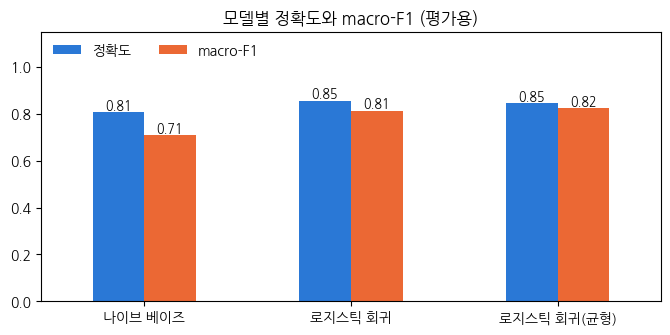

최종 모델: 로지스틱 회귀(균형)


In [13]:
# 정확도와 macro-F1을 모델별로 나란히 그리기
# set_index("모델"): 모델 이름을 행 이름으로 → plot.bar(): 모델마다 막대 2개(정확도, macro-F1)
#   color: 두 막대 색, figsize: 그림 크기, rot=0: x축 글자를 눕히지 않음, ylim: y축 범위
ax = scores.set_index("모델").plot.bar(color=["#2a78d6", "#eb6834"], figsize=(8, 3.5), rot=0, ylim=(0, 1.15))

# 막대마다 위에 점수를 소수 둘째 자리로 표시
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", fontsize=9)

# x축 이름(비움), 제목, 범례(왼쪽 위, 가로 2칸, 테두리 없음)
ax.set_xlabel("")
ax.set_title("모델별 정확도와 macro-F1 (평가용)")
ax.legend(loc="upper left", ncol=2, frameon=False)

# 그래프 화면에 표시
plt.show()

# macro-F1이 가장 높은 모델을 최종 모델로 선택
# sort_values(..., ascending=False): macro-F1 큰 순서로 정렬 → ["모델"].iloc[0]: 1위 모델 이름
best_name = scores.sort_values("macro-F1", ascending=False)["모델"].iloc[0]
# 모델 사전에서 그 이름의 (이미 학습된) 모델을 꺼냄
best = models[best_name]

# 최종 모델 이름 출력
print("최종 모델:", best_name)

✅ **결과 확인:** 정확도가 가장 높은 모델과 macro-F1이 가장 높은 모델이 같은가요? 다르다면 **무엇을 기준으로 고를지**는 업무 목적에 달려 있습니다(정리 참고).

---
## 4. 분석 결과
| 번호 | 결과 |
|---|---|
| 4-1 | 유형별 성적표 (정밀도·재현율·F1) |
| 4-2 | 혼동 행렬: 어떤 유형을 어떤 유형으로 헷갈렸나 |
| 4-3 | 유형별 핵심 단어 |
| 4-4 | 틀린 문의 직접 읽기 |
| 4-5 | 새 문의 넣어 보기 |

### 4-1. 유형별 성적표
| 지표 | 뜻 (예: 은행·카드) |
|---|---|
| 정밀도 (precision) | 모델이 '은행·카드'라고 한 것 중 진짜 은행·카드 비율 |
| 재현율 (recall) | 진짜 은행·카드 중 모델이 찾아낸 비율 |
| F1 | 정밀도와 재현율의 조화 평균 |
| support | 평가용에 있는 그 유형의 문의 수 |

In [14]:
# classification_report: 유형별 정밀도·재현율·F1·문의 수를 표로 만들어 주는 함수
from sklearn.metrics import classification_report

# 최종 모델로 평가용 예측
pred = best.predict(A_test)

# 유형별 성적표 (digits=3: 소수 셋째 자리)
# labels=ORDER: 유형을 ORDER 순서로 표시
print(classification_report(y_test, pred, labels=ORDER, digits=3))

              precision    recall  f1-score   support

       은행·카드      0.974     0.942     0.958       120
       자동차보험      0.823     0.899     0.859       119
   질병·상해 보험금      0.934     0.796     0.859       284
    재물·배상 보험      0.681     0.839     0.752        56
   보험 계약·보험료      0.604     0.797     0.688        69

    accuracy                          0.846       648
   macro avg      0.803     0.855     0.823       648
weighted avg      0.864     0.846     0.850       648



### 4-2. 혼동 행렬

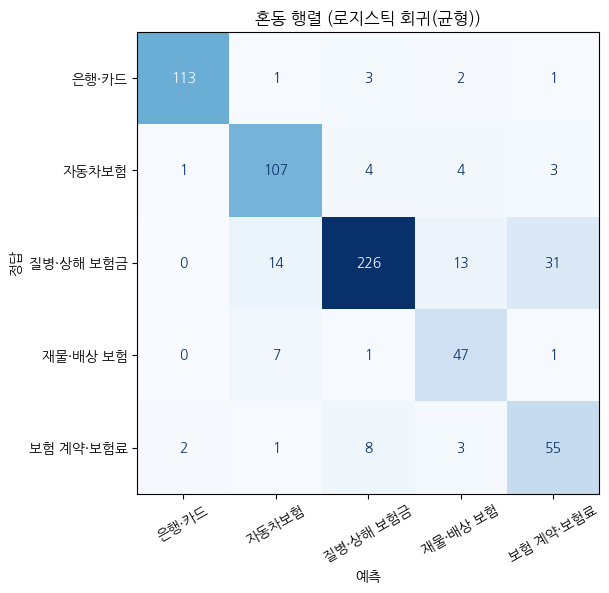

In [15]:
# ConfusionMatrixDisplay: 혼동 행렬(정답과 예측을 비교한 표)을 그리는 도구
from sklearn.metrics import ConfusionMatrixDisplay

# 가로 = 모델 예측, 세로 = 정답, 대각선 = 맞힌 문의 수
# plt.subplots(): 그림(fig)과 그래프 칸(ax)을 만듦
fig, ax = plt.subplots(figsize=(7, 6))

# from_predictions(정답, 예측): 두 목록을 비교해 칸마다 문의 수를 세고 파란색 농도로 그림
#   labels=ORDER: 유형 순서, colorbar=False: 색 막대 숨김, ax: 그릴 칸, xticks_rotation=30: x축 글자 30도 기울임
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=ORDER, cmap="Blues",
                                        colorbar=False, ax=ax, xticks_rotation=30)

# x축 이름, y축 이름, 제목 (f-문자열로 최종 모델 이름을 넣음)
ax.set_xlabel("예측")
ax.set_ylabel("정답")
ax.set_title(f"혼동 행렬 ({best_name})")

# 그래프 화면에 표시
plt.show()

✅ **결과 확인:** 대각선이 아닌 칸 중 숫자가 큰 곳을 찾아보세요. 예를 들어 '질병·상해 보험금'과 '보험 계약·보험료'가 서로 헷갈린다면, "보험금 청구하려고요"처럼 **첫마디만으로는 구분이 어려운 문의** 때문일 수 있습니다.

### 4-3. 유형별 핵심 단어
로지스틱 회귀는 단어마다 유형별 **가중치**를 배웁니다. 가중치가 클수록 그 유형이라고 판단하는 데 크게 쓰인 단어입니다.

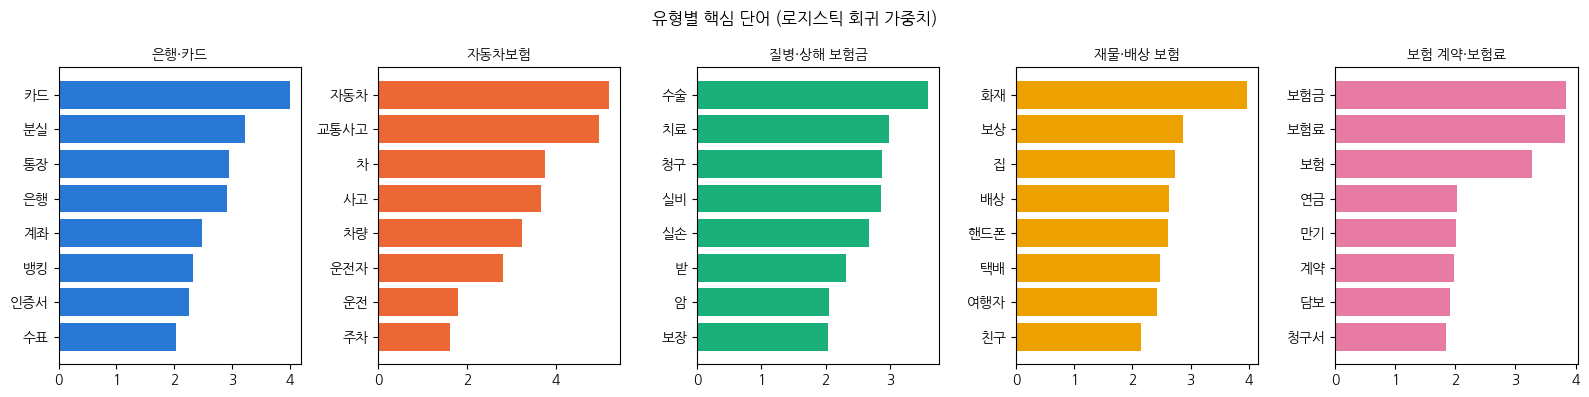

In [16]:
# 단어 사전의 단어들 (가중치와 같은 순서)
# get_feature_names_out(): 행렬의 열 순서대로 단어를 담은 배열
words = tfidf.get_feature_names_out()

# 핵심 단어를 볼 모델 (최종 모델이 나이브 베이즈면 로지스틱 회귀로 대신 봄)
# hasattr(best, "coef_"): 최종 모델에 가중치(coef_)가 있으면 True (로지스틱 회귀만 있음)
lr = best if hasattr(best, "coef_") else models["로지스틱 회귀"]

# 유형마다 가중치가 가장 큰 단어 8개를 가로 막대로 (유형 5개 → 칸 5개)
# plt.subplots(1, 5): 가로로 그래프 칸 5개
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

# 칸 하나에 유형 하나씩 ORDER 순서로 그림
for ax, k in zip(axes, ORDER):
    # lr.classes_: 모델이 기억한 유형 순서, coef_: (유형 수 × 단어 수) 가중치 행렬
    weights = lr.coef_[list(lr.classes_).index(k)]         # 유형 k의 단어별 가중치
    top = weights.argsort()[::-1][:8]                      # 가중치 큰 순서로 8개 위치
    # [::-1]로 뒤집어서 가중치가 큰 단어가 맨 위에 오게 가로 막대를 그림
    ax.barh(words[top][::-1], weights[top][::-1], color=COLORS[k])
    # 칸 제목은 유형 이름
    ax.set_title(k, fontsize=10)

# 그림 전체 제목, 칸끼리 겹치지 않게 간격 조정, 화면에 표시
fig.suptitle("유형별 핵심 단어 (로지스틱 회귀 가중치)")
plt.tight_layout()
plt.show()

✅ **결과 확인:** 사람이 봐도 그 유형다운 단어인가요? `카드`, `통장`처럼 당연한 단어도 있지만, 데이터에 자주 나온 **특정 표현**이 들어 있을 수도 있습니다.

### 4-4. 틀린 문의 직접 읽기

In [17]:
# 평가용 문의 중 틀린 것만 모으기
# data.loc[X_test.index, 열들]: 평가용 문의의 행 번호로 ID·첫질문·유형을 꺼냄
# .assign(예측=pred): 예측 유형을 '예측' 열로 붙인 새 표
result = data.loc[X_test.index, ["ID", "첫질문", "유형"]].assign(예측=pred)

# 정답(유형)과 예측이 다른 행만 고름
wrong = result[result["유형"] != result["예측"]]

# 틀린 문의 수 / 평가용 문의 수 출력
print(f"틀린 문의: {len(wrong)}개 / {len(result)}개")

# 앞 10개 보기
# 표에서 한 칸에 보여 줄 최대 글자 수를 80으로 설정
pd.set_option("display.max_colwidth", 80)
wrong.head(10)

틀린 문의: 100개 / 648개


,ID,첫질문,유형,예측
507,A7741,보험금 청구 문의드립니다.,질병·상해 보험금,보험 계약·보험료
2217,A19216,보험청구를 팩스로 보내려고 하는데 어떻게 하면 되나요?,질병·상해 보험금,보험 계약·보험료
3195,A31246,지금 공항에서 해외 출국전인데요,보험 계약·보험료,은행·카드
947,A8771,자전거 타고 가다가 앞에 오는 차와 부딪쳤는데 이거 어디서 보상 받나요?,질병·상해 보험금,자동차보험
2802,A28914,보험금 청구에 드는 서류가 뭐가 있나요?,보험 계약·보험료,질병·상해 보험금
1839,A14065,다행입니다.,은행·카드,자동차보험
1176,A9169,보험사기 몇년뒤 걸릴 수 있나요?,보험 계약·보험료,자동차보험
2637,A20405,의료실비보험을 가입한 사람이 70%가 넘어간다는 것은 무엇을 의미할까요?,질병·상해 보험금,보험 계약·보험료
2280,A19333,이번에 구제역 때문에 백신접종을 했는데 백신후유증으로 송아지가 유산되었는데요.,재물·배상 보험,자동차보험
2378,A19583,책임보험에 대해서 문의드립니다.,자동차보험,재물·배상 보험


✅ **결과 확인:** 틀린 이유를 세 가지로 나눠 보세요.
1. **모델이 틀림** (첫 질문에 유형을 알 수 있는 단어가 있는데 틀림)
2. **첫 질문만으로는 알 수 없음** ("보험금 청구하려고요")
3. **정답이 의심스러움** (사람이 정한 정답이 틀렸을 수도 있음)

### 4-5. 새 문의 넣어 보기
**✏️ [입력]** 문의 문장을 바꿔 보세요. 유형별 확률이 함께 나옵니다.

In [18]:
# ===== ✏️ [입력] 새 문의 =====
# 넣어 볼 문의 문장들의 리스트
new_questions = [
    "카드를 잃어버렸는데 정지해 주세요",
    "주차하다가 옆 차를 긁었어요",
    "도수치료 받았는데 실비 청구 되나요?",
    "아랫집 천장에 물이 샌다고 연락이 왔어요",
    "보험료가 두 달 밀렸는데 어떻게 되나요?",
]
# ============================

# 새 문의도 학습 때와 같은 방법으로 단어 나누기 → TF-IDF 숫자로 바꾸기
# 문장마다 to_words로 단어 목록을 만들고, 학습 때 만든 tfidf로 숫자 행렬로 바꿈
A_new = tfidf.transform([to_words(q) for q in new_questions])

# 유형별 확률 표 (행 = 문의, 열 = 유형, 값 = %)
# predict_proba(): 문의마다 유형별 확률(0~1) → * 100으로 백분율
# columns=best.classes_: 열 이름을 모델의 유형 순서로, index=new_questions: 행 이름을 문의 문장으로
# [ORDER]: 열을 ORDER 순서로 다시 정렬, round(1): 소수 첫째 자리
proba = pd.DataFrame(best.predict_proba(A_new) * 100, columns=best.classes_, index=new_questions)[ORDER].round(1)

# idxmax(axis=1): 행마다 확률이 가장 큰 열 이름(유형) → 맨 앞(0번 위치)에 '예측 유형' 열로 넣기
proba.insert(0, "예측 유형", proba.idxmax(axis=1))

# 확률 표 보기
proba

,예측 유형,은행·카드,자동차보험,질병·상해 보험금,재물·배상 보험,보험 계약·보험료
카드를 잃어버렸는데 정지해 주세요,은행·카드,93.9,1.6,1.3,1.7,1.5
주차하다가 옆 차를 긁었어요,자동차보험,3.0,90.6,2.2,2.0,2.2
도수치료 받았는데 실비 청구 되나요?,질병·상해 보험금,0.3,0.3,97.9,0.5,1.0
아랫집 천장에 물이 샌다고 연락이 왔어요,재물·배상 보험,6.9,4.3,3.0,81.1,4.7
보험료가 두 달 밀렸는데 어떻게 되나요?,보험 계약·보험료,7.5,7.1,8.1,6.7,70.6


### 결과 저장

In [19]:
# 평가용 문의별 정답과 예측 저장
# to_csv: 표를 CSV 파일로 저장 (index=False: 행 번호 저장 안 함, utf-8-sig: 엑셀 한글 깨짐 방지)
result.to_csv("predictions.csv", index=False, encoding="utf-8-sig")

# 저장한 파일 이름 출력
print("저장 완료: inquiry_dataset.csv, predictions.csv")

저장 완료: inquiry_dataset.csv, predictions.csv


---
## 정리

### ✅ 한 줄 정리
**고객 첫 질문을 단어로 나누고 TF-IDF 숫자로 바꾼 뒤, 분류 모델이 문의 유형을 맞히도록 학습시켰다.**

### 🗂️ 만든 파일
| 파일 | 내용 |
|---|---|
| `inquiry_dataset.csv` | 정제 데이터셋 (ID, 첫질문, 단어, 유형) |
| `predictions.csv` | 평가용 문의의 정답과 예측 |

### 🤔 생각해 볼 점 (한계)
| 한계 | 설명 |
|---|---|
| **정답이 사람 한 명의 판단** | 키워드로 임시 정답을 만들고 한 사람이 고쳤습니다. 여러 사람이 정답을 달고 일치하는지 확인하는 것이 더 믿을 만합니다. |
| **유형 기준에 정답이 없음** | "교통사고로 다쳐서 실비 청구"는 자동차보험일까요, 질병·상해 보험금일까요? 회사마다 기준이 다릅니다. |
| **첫마디만으로 알 수 없는 문의** | "보험금 청구하려고요"처럼 첫 질문에 유형 단서가 없으면 맞히기 어렵습니다. 대화를 더 보면 정확해지지만, 그만큼 연결이 늦어집니다. |
| **비슷한 문의가 학습·평가에 나뉘어 들어감** | 이 데이터에는 문장만 조금 바꾼 대화가 많습니다. 평가용 문의 중 약 10%는 학습용에 매우 비슷한 문장이 있어서, 실제 현장보다 점수가 높게 나왔을 수 있습니다. |
| **정확도 vs macro-F1** | 많이 들어오는 문의를 잘 맞히는 게 중요하면 정확도, 적게 들어오는 유형도 놓치면 안 되면 macro-F1을 기준으로 고릅니다. |


**참고:** [Kiwi (kiwipiepy)](https://github.com/bab2min/kiwipiepy) · [scikit-learn 텍스트 특징 추출](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction) · [scikit-learn 분류 평가](https://scikit-learn.org/stable/modules/model_evaluation.html)